# easy_volcano examples

This notebook generates the example figures. It uses *airway* dataset and DESeq2 results
(airway smooth muscle cells treated with dexamethasone).

Every figure is saved to `figures/`.

## Contents

1. [Simple plot](#simple-plot)
    - [Load the data](#load-the-data)
    - [Default plot](#default-plot)
2. [Customisation](#customisation)
    - [Legend position, label column and number of labels](#legend-position-label-column-and-number-of-labels)
    - [Thresholds and custom lines](#thresholds-and-custom-lines)
    - [Default colours and marker](#default-colours-and-marker)
    - [How highlights work](#how-highlights-work)
    - [The `{...}` pattern: options passed to matplotlib](#the-pattern-options-passed-to-matplotlib)
    - [Custom colours with highlights](#custom-colours-with-highlights)
    - [Highlight low expression genes](#highlight-low-expression-genes)
    - [Spotlight](#spotlight)
3. [Going further](#going-further)
    - [Several panels and clipping p-values](#several-panels-and-clipping-p-values)
    - [Master example](#master-example)
    - [Label the genes you care about](#label-the-genes-you-care-about)
    - [Highlight with a rule over any columns](#highlight-with-a-rule-over-any-columns)
    - [Layered highlights: later wins](#layered-highlights-later-wins)
    - [Keep going with matplotlib](#keep-going-with-matplotlib)
    - [Export for Illustrator](#export-for-illustrator)

In [1]:
import easy_volcano as ev
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

<a id="simple-plot"></a>

## Simple plot

<a id="load-the-data"></a>

### Load the data

In [2]:
df = pd.read_csv("/Users/rlannes/Code/easyvolcano/data/easy_volcano_airway_example.tsv", sep='\t')
df["gene_name"] = df.index

<a id="default-plot"></a>

### Default plot

By default the 5 most over- and under-expressed genes are labelled.
The adjusted p-value cutoff is 1e-2 by default; airway has a very strong signal, so we use 1e-6 here.

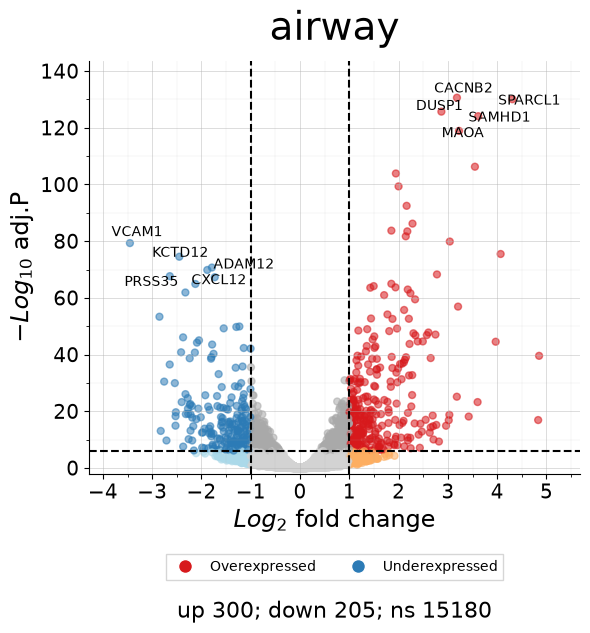

In [3]:
(fig, ax) = ev.plot_volcano(df, y_thr=10**(-6), title="airway")
fig.savefig(FIG_DIR / "default.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="customisation"></a>

## Customisation

<a id="legend-position-label-column-and-number-of-labels"></a>

### Legend position, label column and number of labels

- `legend_loc` has three presets: `"top"`, `"bottom"` and `"right"`. More options are available through `legend_kwargs`.
- Labels use the index by default, but any column can be used instead with `label_column="gene_name"`.
- `label_top` labels the top X up- and down-regulated genes.

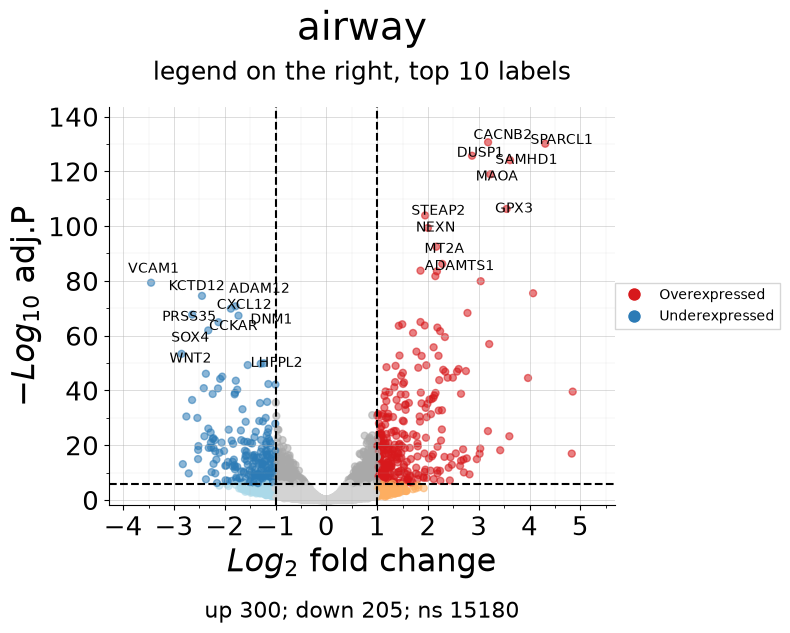

In [4]:
(fig, ax) = ev.plot_volcano(df, y_thr=10**(-6),  title="airway",
                            subtitle="legend on the right, top 10 labels", legend_loc='right', width=8, 
                            label_column="gene_name", label_top = 10)
fig.savefig(FIG_DIR / "legend_right_label_top.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="thresholds-and-custom-lines"></a>

### Thresholds and custom lines

Changing a threshold moves both the threshold lines and the colours.
You can also add your own horizontal or vertical lines by passing a dictionary, or a list of dictionaries,
with the position (`x` or `y`) plus any matplotlib line option.
For `h_lines`, `y` is a p-value (here `1e-20`, drawn at 20 on the -log10 axis).

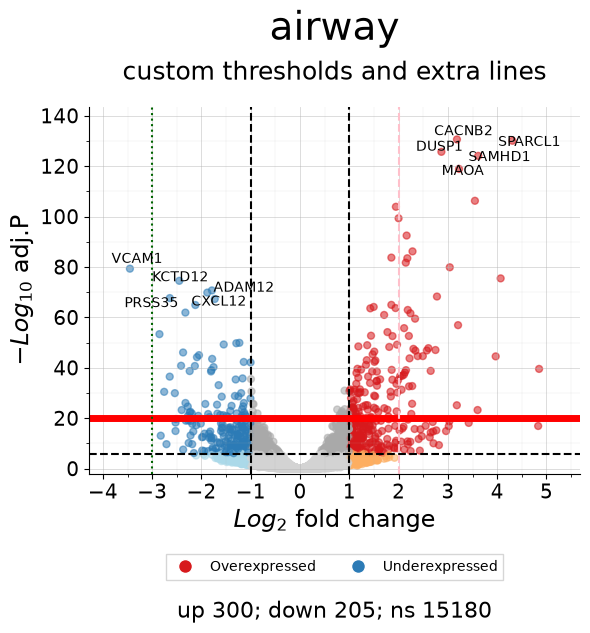

In [5]:
(fig, ax) = ev.plot_volcano(df, y_thr=10**(-6),  title="airway",
                            subtitle="custom thresholds and extra lines", x_thr=1,
                            h_lines={"y": 10**(-20), "linewidth":5, "color":"red", "linestyle" :"-"},
                            v_lines = [{"x": 2, "color":"pink"},
                                        {"x": -3, "linestyle" : "dotted", "color": "darkgreen"}])
fig.savefig(FIG_DIR / "custom_lines.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="default-colours-and-marker"></a>

### Default colours and marker

Every gene gets one of six colours from the two thresholds (p = adjusted p-value, lfc = log2 fold change):

| Parameter | Genes | Default |
|---|---|---|
| `color_up_sig` | p ≤ `y_thr` and lfc ≥ `x_thr` (legend: "Overexpressed") | `"#D7191C"` |
| `color_down_sig` | p ≤ `y_thr` and lfc ≤ -`x_thr` (legend: "Underexpressed") | `"#2C7BB6"` |
| `color_sig` | p ≤ `y_thr` but \|lfc\| < `x_thr` | `"darkgrey"` |
| `color_up` | p > `y_thr` but lfc ≥ `x_thr` | `"#FDAE61"` |
| `color_down` | p > `y_thr` but lfc ≤ -`x_thr` | `"#ABD9E9"` |
| `color_ns` | neither threshold | `"lightgrey"` |

Colours can be any matplotlib colour: a name (`"purple"`), a hex code (`"#762A83"`) or an RGB tuple.
`marker`, `size` and `alpha` change the shape, size and transparency of every point.

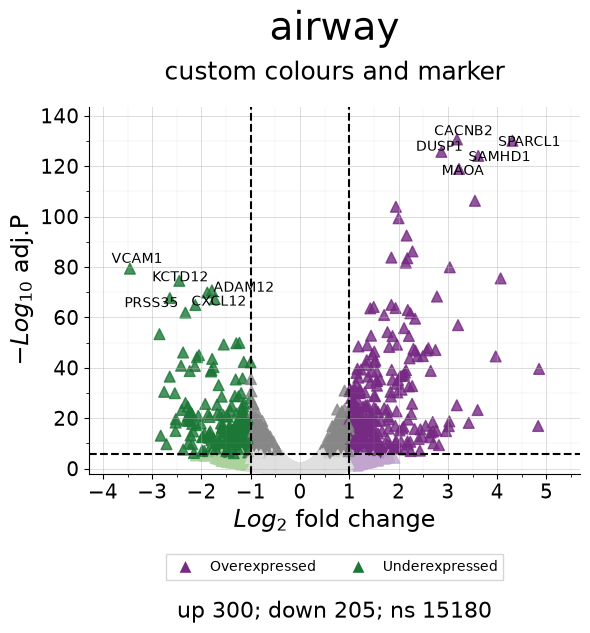

In [6]:
(fig, ax) = ev.plot_volcano(df, y_thr=1e-6, title="airway", subtitle="custom colours and marker",
                            color_up_sig="#762A83", color_down_sig="#1B7837",
                            color_up="#C2A5CF", color_down="#ACD39E",
                            color_sig="#878787", color_ns="#E0E0E0",
                            marker="^", size=60, alpha=0.8)
fig.savefig(FIG_DIR / "custom_colours.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="how-highlights-work"></a>

### How highlights work

`highlights` is a **list of pairs**. Each pair says *which genes* and *how to draw them*:

```python
highlights=[
    (which_genes, how_to_draw),
    (which_genes, how_to_draw),
]
```

For example, "draw FKBP5 and PER1 in red, bigger":

```python
highlights=[ (["FKBP5", "PER1"], {"color": "red", "size": 200}) ]
#             └─ which genes ──┘  └──────── how to draw ───────┘
```

Three rules to remember:

1. **Pairs are applied in order, and the last one wins.** If a gene is matched by two pairs, the later pair's style is used
   (only for the options it sets; the rest are kept from earlier pairs).
2. **Highlighted genes are drawn on top** of all other points, so they are never hidden.
3. **You only change what you write.** Anything you don't set keeps its default (colour, size, transparency, ...).

#### Which genes: three ways to select

| You write | Meaning | Example |
|---|---|---|
| a list of names | these genes | `["FKBP5", "PER1"]` |
| a rule: `lambda d: ...` | every gene for which the rule is true | `lambda d: d["baseMean"] < 100` |
| a True/False column | the genes marked True | `df["padj"] < 1e-10` |

- **Names** are looked up in the index of your table, or in `label_column` if you set it
  (e.g. `label_column="gene_name"` to use symbols while your index holds Ensembl IDs).
  Even a single gene goes in a list: `["FKBP5"]`, not `"FKBP5"`.
- **A rule** reads as: *"given the table `d`, keep the rows where ..."*. `d` is your table (rows with missing values removed),
  so you can use any of its columns. Combine conditions with `&` (and), `|` (or), `~` (not), with each condition in parentheses:
  `lambda d: (d["baseMean"] > 1000) & (d["log2FoldChange"] > 2)`.
  For text, use pandas string methods: `lambda d: d.index.str.startswith("COL")`.

**Tip: check a rule before plotting.** A rule is just a function, so you can call it on your table
and count how many genes it selects:

In [7]:
rule = lambda d: (d["baseMean"] > 1000) & (d["padj"] < 1e-30)
print(rule(df).sum(), "genes selected")
df[rule(df)].head()

79 genes selected


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,gene_name
SAMD4A,3108.159178,1.181014,0.090315,13.074672,4.595436e-39,8.098811e-37,SAMD4A
GPM6B,1091.781725,2.275718,0.179272,12.466887,1.131606e-35,1.723227e-33,GPM6B
INPP5A,1248.528618,1.354023,0.094885,14.263814,3.677904e-46,9.304505e-44,INPP5A
FSTL3,2129.564867,1.773270,0.110690,15.988789,1.529762e-57,6.855521e-55,FSTL3
LMCD1,3663.382040,1.556186,0.121391,12.828198,1.139846e-37,1.843143e-35,LMCD1


<a id="the-pattern-options-passed-to-matplotlib"></a>

### The `{...}` pattern: options passed to matplotlib

Many options in easy_volcano are a **dictionary** (`{"name": value, ...}`), for example the *how to draw* part of a highlight,
`label_format`, `legend_kwargs` or each line in `h_lines`. A dictionary is just a bundle of named options.
easy_volcano hands it to the matplotlib function that draws that element, exactly as if you had typed the options yourself:

```python
{"color": "red", "marker": "D", "edgecolors": "black"}
# is passed on as
ax.scatter(..., color="red", marker="D", edgecolors="black")
```

This is why the possibilities are not limited to what easy_volcano lists: **any option the matplotlib function accepts works**.
When you want something new, look up the matplotlib function in the table below, find the option, and put it in the dictionary.

| Option in easy_volcano | Passed to matplotlib's | Useful keys (examples) |
|---|---|---|
| highlight style `(genes, {...})` | [`ax.scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.scatter.html) | `color`, `size`, `alpha`, `marker`, `edgecolors`, `linewidths`, `zorder` |
| any extra keyword, e.g. `plot_volcano(df, edgecolors="none")` | `ax.scatter`, for every point | same as above |
| `label_format`, `label_genes_format`, `label_gene={...}` | [`ax.text`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.text.html) | `fontsize`, `fontweight`, `fontstyle`, `color` |
| `legend_kwargs` | [`ax.legend`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.legend.html) | `fontsize`, `frameon`, `title`, `ncols` |
| each line in `h_lines` / `v_lines` | [`ax.axhline` / `ax.axvline`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.axhline.html) | `color`, `linestyle`, `linewidth`, `alpha` |

A few things easy_volcano adds on top:

- **Short names** in highlight styles: `size` means matplotlib's `s`, `color` means `c`, and `a` means `alpha`.
  Use one form or the other, not both.
- **Extra keys** in highlight styles, handled by easy_volcano and not passed to matplotlib:
  - `"label": "my genes"` adds the group to the legend,
  - `"label_gene": True` writes the gene names on the plot; a dictionary (`{"fontweight": "bold"}`) also styles those names, like `label_format`.
- **Position keys are reserved**: in text formats, `x`, `y`, `s`, `position` and `text` are set by easy_volcano;
  in `h_lines`/`v_lines`, `y`/`x` is the position (for `h_lines`, `y` is a p-value).

<a id="custom-colours-with-highlights"></a>

### Custom colours with highlights

Select genes with a rule (a `lambda` on the table) or directly with a list of index names.
- Adding a `label` key adds the group to the legend.
- Setting `label_gene` adds the gene names to the plot.

Here shows that ribosomal protein gene are not DE

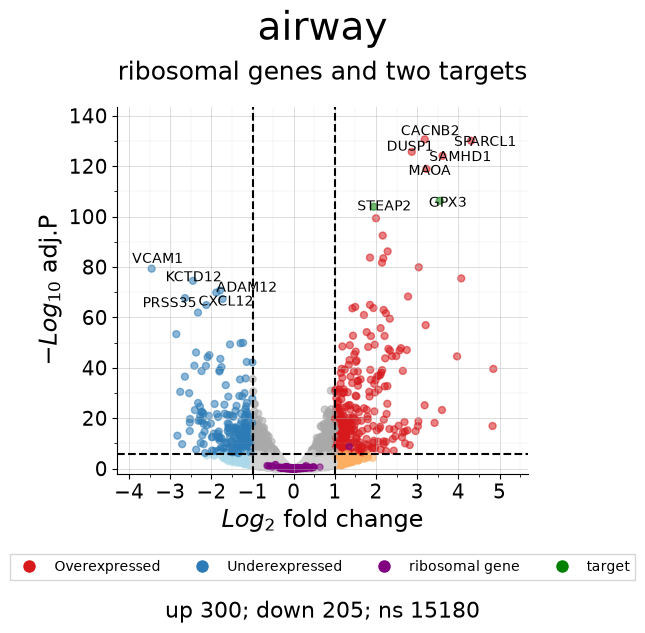

In [8]:
(fig, ax) = ev.plot_volcano(df, y_thr=10**(-6), width=6, title="airway", subtitle="ribosomal genes and two targets", legend_loc='bottom',
                          highlights= [(lambda d: d.index.str.startswith("RPL"),
                                        {"color": "purple", "size": 80, "label": 'ribosomal gene'}), 
                                        (["GPX3", "STEAP2"] , {"color": "green", "label_gene": "True", "label": 'target' })
                                      ]
                           )
fig.savefig(FIG_DIR / "highlights.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="highlight-low-expression-genes"></a>

### Highlight low expression genes

A rule can use any column of the table, here `baseMean`.

One could do the opposite and fade/ hide those.

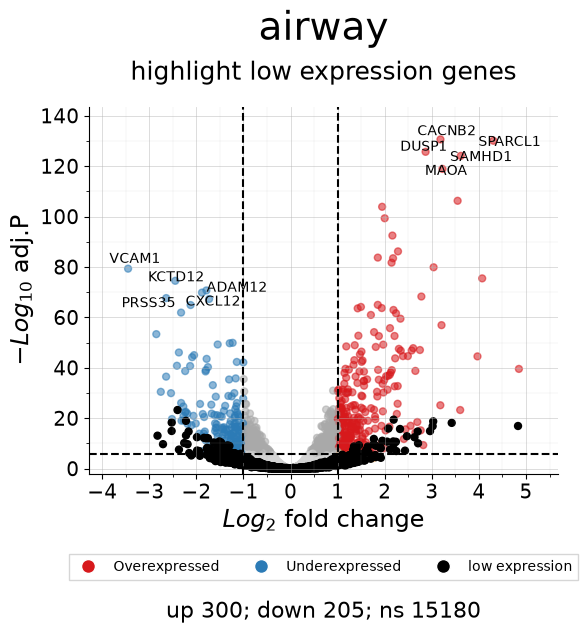

In [9]:
(fig, ax) = ev.plot_volcano(df, y_thr=10**(-6), width=6, title="airway", subtitle="highlight low expression genes", legend_loc='bottom',
                          highlights= [(lambda d: d["baseMean"] < 100, {"alpha": 1, "color":"black", "label": "low expression" })]
                           )
fig.savefig(FIG_DIR / "low_expression.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="spotlight"></a>

### Spotlight

`no_default=True` turns off the default colouring, so only your genes stand out.

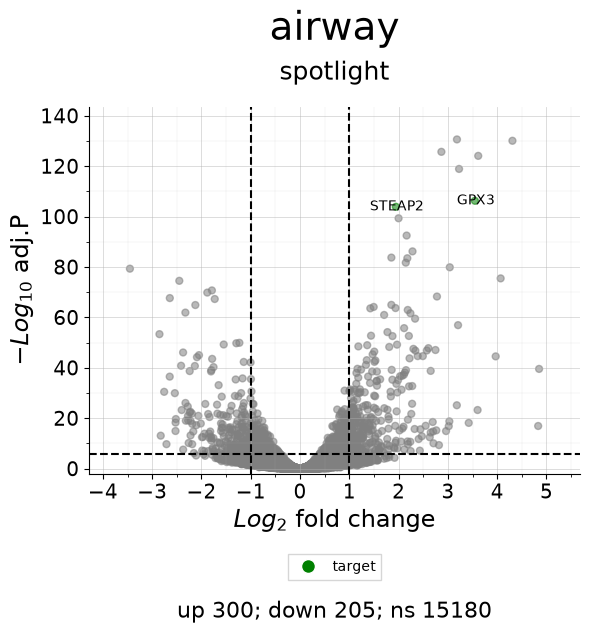

In [10]:
(fig, ax) = ev.plot_volcano(df, y_thr=10**(-6), width=6, title="airway", subtitle="spotlight",
                            no_default=True, label_top=None,
                          highlights= [(["GPX3", "STEAP2"] , {"color": "green", "label_gene": "True", "label": 'target' })]
                           )
fig.savefig(FIG_DIR / "spotlight.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="going-further"></a>

## Going further

<a id="several-panels-and-clipping-p-values"></a>

### Several panels and clipping p-values

- Pass `ax=` to draw into an existing figure, here two panels side by side.
- `clip_pval` (right) avoids a squashed plot when some p-values are extremely small or zero.

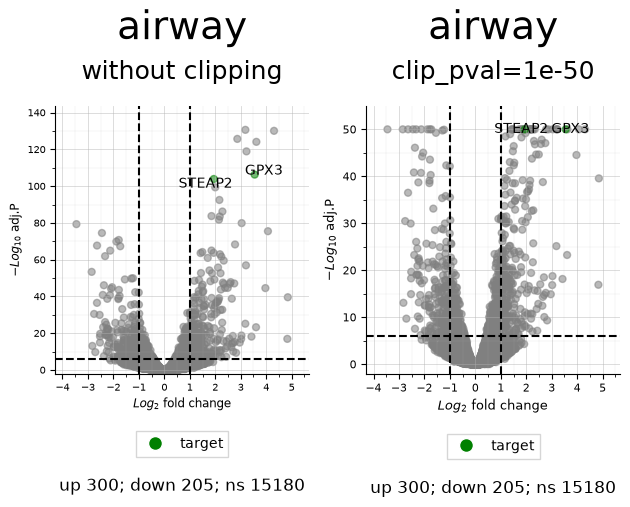

In [11]:
fig, axes = plt.subplots(ncols=2)
(fig, ax) = ev.plot_volcano(df, ax=axes[0], y_thr=10**(-6), width=6, title="airway", subtitle="without clipping",
                            no_default=True, label_top=None, font_size_text_summary=12,
                          highlights= [(["GPX3", "STEAP2"] , {"color": "green", "label_gene": "True", "label": 'target' })]
                           )
(fig, ax) = ev.plot_volcano(df, ax=axes[1], y_thr=10**(-6), width=6, title="airway", subtitle="clip_pval=1e-50",
                            no_default=True, label_top=None, clip_pval=10**(-50),font_size_text_summary=12,
                          highlights= [(["GPX3", "STEAP2"] , {"color": "green", "label_gene": "True", "label": 'target' })]
                           )
fig.savefig(FIG_DIR / "clip_pval_panels.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="master-example"></a>

### Master example 

Airway cells were treated with dexamethasone, a glucocorticoid. In one call:
- lowly expressed genes are faded (a rule on `baseMean`),
- collagens are picked by a rule on the gene name,
- canonical glucocorticoid targets are given as a plain list, drawn bigger with an outline, and labelled in bold,
- title, subtitle and legend are stacked on top without overlapping.

Highlights are applied in order: a gene matched by several layers keeps the last one.

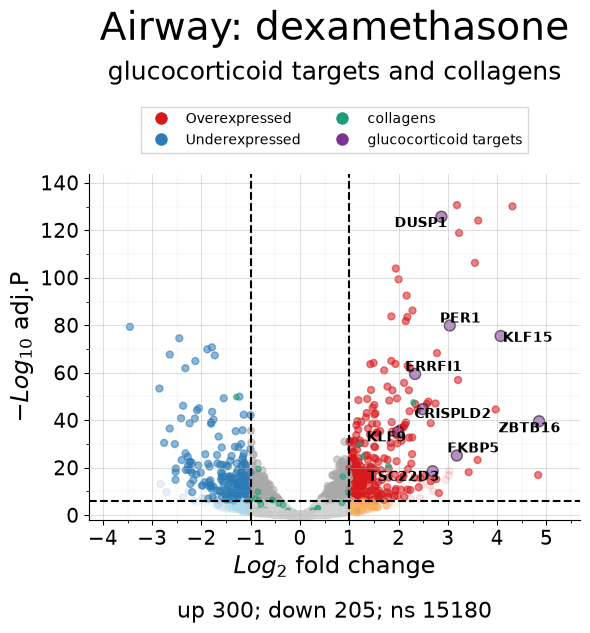

In [12]:
gc_targets = ["FKBP5", "TSC22D3", "PER1", "KLF15", "ZBTB16",
              "DUSP1", "CRISPLD2", "KLF9", "ERRFI1"]

fig, ax = ev.plot_volcano(
    df, y_thr=1e-6, label_top=None, label_avoid_self=True,
    title="Airway: dexamethasone",
    subtitle="glucocorticoid targets and collagens",
    legend_loc="top", legend_nrows=2,
    highlights=[
        # 1. fade lowly expressed genes
        (lambda d: d["baseMean"] < 50, {"alpha": 0.1}),
        # 2. a gene family picked by a rule on the index
        (lambda d: d.index.str.startswith("COL"),
         {"color": "#1b9e77", "size": 60, "label": "collagens"}),
        # 3. a hand-picked list, outlined and labelled in bold
        (gc_targets,
         {"color": "#7b3294", "size": 250, "edgecolors": "black", "linewidths": 1,
          "label": "glucocorticoid targets", "label_gene": {"fontweight": "bold"}}),
    ])
fig.savefig(FIG_DIR / "hero.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="label-the-genes-you-care-about"></a>

### Label the genes you care about

`label_top` labels the most significant genes on each side; `label_genes` adds your own.
`label_genes_format` styles only your genes (any matplotlib text option), and
`label_genes_line` draws a line from a label to its point when the label had to move.

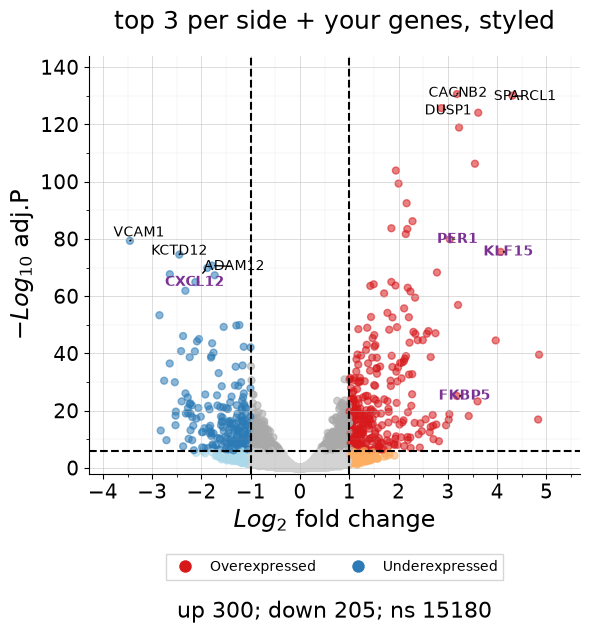

In [13]:
fig, ax = ev.plot_volcano(
    df, y_thr=1e-6, label_top=3,
    label_genes=["FKBP5", "KLF15", "PER1", "CXCL12"],
    label_genes_format={"fontweight": "bold", "color": "#7b3294"},
    label_genes_line=True, label_min_arrow_len=5,
    subtitle="top 3 per side + your genes, styled")
fig.savefig(FIG_DIR / "label_genes.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="highlight-with-a-rule-over-any-columns"></a>

### Highlight with a rule over any columns

A selector can be a function of the table: here, highly expressed **and** very significant genes.
The style dict accepts any `ax.scatter` argument (`marker`, `edgecolors`, `linewidths`, ...).

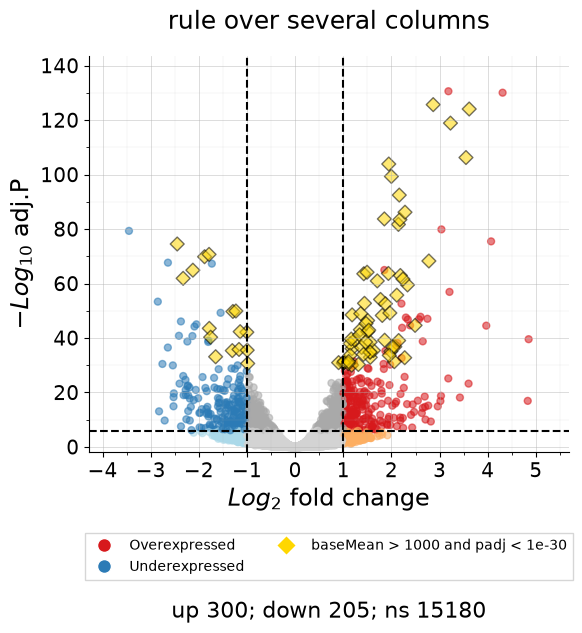

In [14]:
fig, ax = ev.plot_volcano(
    df, y_thr=1e-6, label_top=None,
    subtitle="rule over several columns", legend_nrows=2,
    highlights=[
        (lambda d: (d["baseMean"] > 1000) & (d["padj"] < 1e-30),
         {"marker": "D", "size": 50, "color": "gold", "edgecolors": "black",
          "label": "baseMean > 1000 and padj < 1e-30"}),
    ])
fig.savefig(FIG_DIR / "rule_highlight.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="layered-highlights-later-wins"></a>

### Layered highlights: later wins

All collagens are green; collagens that also change more than 2-fold are then restyled by a second layer
(darker, bigger, outlined and labelled).

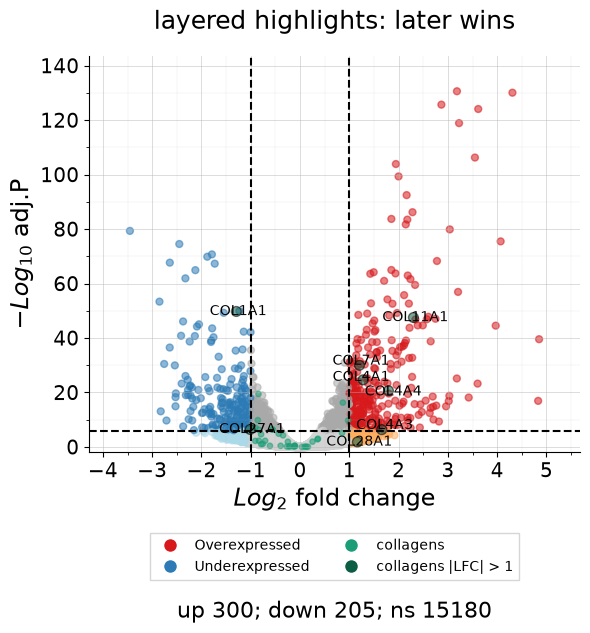

In [15]:
fig, ax = ev.plot_volcano(
    df, y_thr=1e-6, label_top=None,
    subtitle="layered highlights: later wins", legend_nrows=2,
    highlights=[
        (lambda d: d.index.str.startswith("COL"),
         {"color": "#1b9e77", "size": 60, "label": "collagens"}),
        (lambda d: d.index.str.startswith("COL") & (d["log2FoldChange"].abs() > 1),
         {"color": "#0b5d44", "size": 200, "edgecolors": "black",
          "label": "collagens |LFC| > 1", "label_gene": True}),
    ])
fig.savefig(FIG_DIR / "layers.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="keep-going-with-matplotlib"></a>

### Keep going with matplotlib

`plot_volcano` returns `(fig, ax)`, so anything matplotlib can do still works afterwards:
here a shaded region and an annotation with an arrow.

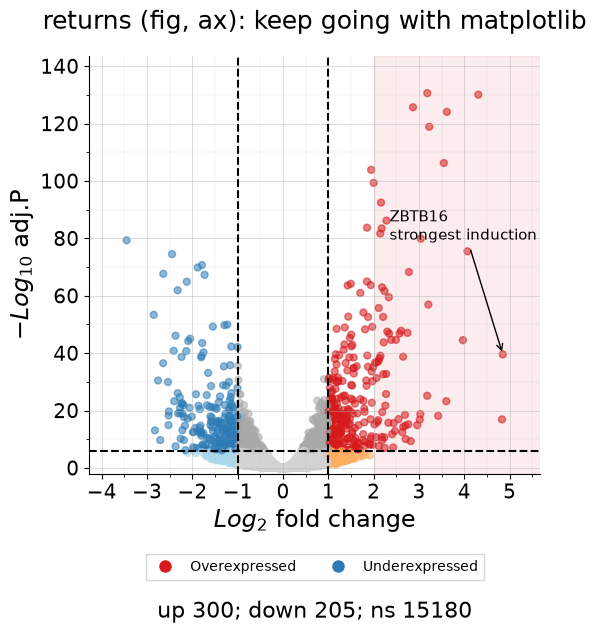

In [16]:
fig, ax = ev.plot_volcano(df, y_thr=1e-6, label_top=None,
                          subtitle="returns (fig, ax): keep going with matplotlib")
xlim = ax.get_xlim()
ax.axvspan(2, xlim[1], color="#D7191C", alpha=0.08, zorder=0)   # shade a region
ax.set_xlim(xlim)                                                # keep the original limits
gene = "ZBTB16"
xy = (df.loc[gene, "log2FoldChange"], -np.log10(df.loc[gene, "padj"]))
ax.annotate(f"{gene}\nstrongest induction", xy=xy, xytext=(xy[0] - 2.5, xy[1] + 40),
            arrowprops=dict(arrowstyle="->"), fontsize=11)
fig.savefig(FIG_DIR / "matplotlib_after.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

<a id="export-for-illustrator"></a>

### Export for Illustrator

Text is saved as editable text in PDF. With `rasterize=True` the points become an image while
text, axes and lines stay vector, so the file stays small and still opens quickly in Illustrator.

In [17]:
for raster in (False, True):
    path = FIG_DIR / f"volcano_rasterize_{raster}.pdf"
    fig, ax = ev.plot_volcano(df, y_thr=1e-6, rasterize=raster, savefig=path)
    plt.close(fig)
    print(f"rasterize={raster}: {path.stat().st_size / 1e3:.0f} kB")

rasterize=False: 2625 kB


rasterize=True: 57 kB
